# Task 1 – Load and inspect the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("zomato.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (51717, 17)


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [3]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


In [9]:
print(df.columns.tolist())

['url', 'address', 'name', 'online_order', 'book_table', 'rating', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisine', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']


In [10]:
# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Rename dataset columns
df = df.rename(columns={
    "rate": "rating",
    "cuisines": "cuisine",
    "approx_cost(for two people)": "cost",
    "approx cost(for two people)": "cost"
})

print(df.columns.tolist())

['url', 'address', 'name', 'online_order', 'book_table', 'rating', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisine', 'cost', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']


# Task 2 – Handle missing values and outliers

In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
url                    0
address                0
name                   0
online_order           0
book_table             0
rating             10052
votes                  0
phone               1208
location              21
rest_type            227
dish_liked         28078
cuisine               45
cost                 346
reviews_list           0
menu_item              0
listed_in(type)        0
listed_in(city)        0
dtype: int64


In [14]:
# Convert rating into numeric values
df["rating"] = pd.to_numeric(
    df["rating"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Remove commas and convert cost into numeric values
df["cost"] = pd.to_numeric(
    df["cost"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

print(df[["rating", "cost"]].head())

   rating   cost
0     4.1  800.0
1     4.1  800.0
2     3.8  800.0
3     3.7  300.0
4     3.8  600.0


In [15]:
# Fill missing numeric values with median
df["rating"] = df["rating"].fillna(df["rating"].median())
df["cost"] = df["cost"].fillna(df["cost"].median())

# Fill missing categorical values
df["cuisine"] = df["cuisine"].fillna("Unknown")
df["location"] = df["location"].fillna("Unknown")

print("Missing values after handling:")
print(df[["rating", "cost", "cuisine", "location"]].isnull().sum())

Missing values after handling:
rating      0
cost        0
cuisine     0
location    0
dtype: int64


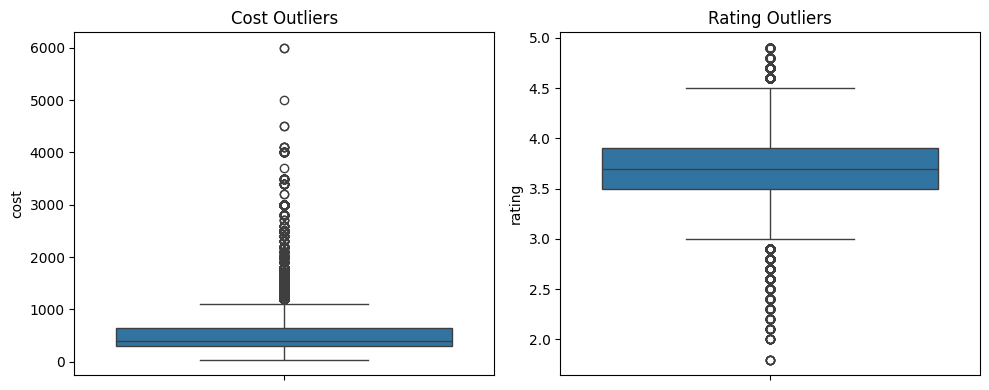

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["cost"])
plt.title("Cost Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["rating"])
plt.title("Rating Outliers")

plt.tight_layout()
plt.show()

In [17]:
# Calculate IQR for cost
Q1 = df["cost"].quantile(0.25)
Q3 = df["cost"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Cap extreme cost values
df["cost"] = df["cost"].clip(
    lower=lower_limit,
    upper=upper_limit
)

# Check cost after handling outliers
print(df["cost"].describe())

count    51717.000000
mean       511.657192
std        303.205492
min         40.000000
25%        300.000000
50%        400.000000
75%        650.000000
max       1175.000000
Name: cost, dtype: float64


# Task 3 – Encode categorical variables and scale numerical data

In [18]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Create target variable
df["high_rating"] = (df["rating"] > 4.0).astype(int)

# Select input features
X = df[["cuisine", "location", "cost"]]
y = df["high_rating"]

# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("cuisine", OneHotEncoder(handle_unknown="ignore"), ["cuisine"]),
        ("location", OneHotEncoder(handle_unknown="ignore"), ["location"]),
        ("cost", StandardScaler(), ["cost"])
    ]
)

# Transform the features
X_encoded = preprocessor.fit_transform(X)

print("Encoded Data Shape:", X_encoded.shape)
print("Target Classes:")
print(y.value_counts())

Encoded Data Shape: (51717, 2819)
Target Classes:
high_rating
0    42501
1     9216
Name: count, dtype: int64


# Task 4 – Train Logistic Regression and Random Forest

In [19]:
from sklearn.model_selection import train_test_split

# Use the original features
X = df[["cuisine", "location", "cost"]]
y = df["high_rating"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (41373, 3)
Testing Data: (10344, 3)


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train models
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [21]:
# Predict probabilities
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
logistic_auc = roc_auc_score(y_test, logistic_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Logistic Regression ROC-AUC:", round(logistic_auc, 4))
print("Random Forest ROC-AUC:", round(rf_auc, 4))

# Find the better model
if logistic_auc > rf_auc:
    print("Logistic Regression performed better.")
elif rf_auc > logistic_auc:
    print("Random Forest performed better.")
else:
    print("Both models performed equally.")

Logistic Regression ROC-AUC: 0.9394
Random Forest ROC-AUC: 0.9928
Random Forest performed better.


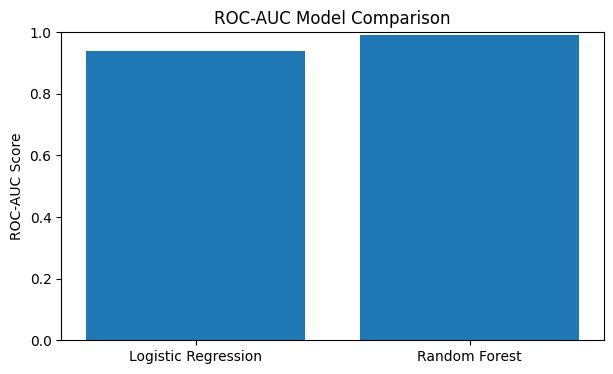

In [22]:
models = ["Logistic Regression", "Random Forest"]
scores = [logistic_auc, rf_auc]

plt.figure(figsize=(7, 4))
plt.bar(models, scores)

plt.title("ROC-AUC Model Comparison")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)
plt.show()

# Task 5 – Handle imbalance using SMOTE and tune Random Forest

In [23]:
print("Class Distribution:")
print(y_train.value_counts())

class_counts = y_train.value_counts()

imbalance_ratio = class_counts.min() / class_counts.max()

print("Minority-to-majority ratio:", round(imbalance_ratio, 3))

Class Distribution:
high_rating
0    34000
1     7373
Name: count, dtype: int64
Minority-to-majority ratio: 0.217


In [24]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [25]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [26]:
# Apply SMOTE only if the minority class is much smaller
if imbalance_ratio < 0.7:
    sampler = SMOTE(random_state=42)
    print("SMOTE will be applied.")
else:
    sampler = "passthrough"
    print("Classes are reasonably balanced. SMOTE is not required.")

rf_pipeline = ImbPipeline([
    ("preprocessing", preprocessor),
    ("smote", sampler),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

SMOTE will be applied.


In [ ]:
# Parameters to test
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)

# Train GridSearchCV
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross-Validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [ ]:
best_model = grid_search.best_estimator_

# Predict probabilities on the original test data
final_prob = best_model.predict_proba(X_test)[:, 1]

final_auc = roc_auc_score(y_test, final_prob)

print("Final Test ROC-AUC:", round(final_auc, 4))